# Phase 3 — Fixed-Parameter Enhancement Layer (URI-CADS)

Adds CLAHE + denoising + gamma correction as a **fixed-parameter** preprocessing step, applied before the same architecture from Phase 2. This is the second control condition -- Phase 6's optimizer will later tune these same parameters instead of using fixed values, so this notebook also builds the actual `enhance_ultrasound()` function that gets reused there.

**Do not touch Phase 2's results** -- this is a separate, additional baseline for comparison, not a replacement.

## Setup (identical to Phase 2 -- same cached zip + saved manifest)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

DRIVE_PROJECT_ROOT = '/content/drive/MyDrive/URI-CADS dataset'
DRIVE_ZIP_PATH = f'{DRIVE_PROJECT_ROOT}/uri_cads_archive.zip'
DRIVE_CHECKPOINTS_PATH = f'{DRIVE_PROJECT_ROOT}/checkpoints'
MANIFEST_SAVE_PATH = f'{DRIVE_PROJECT_ROOT}/manifest_with_splits.pkl'

LOCAL_ZIP_PATH = '/content/uri_cads_archive.zip'
LOCAL_DATA_DIR = '/content/uri_cads_data'
LOCAL_DATASET_DIR = os.path.join(LOCAL_DATA_DIR, 'bbdd_kidney')

os.makedirs(DRIVE_CHECKPOINTS_PATH, exist_ok=True)
print('Zip exists on Drive:', os.path.exists(DRIVE_ZIP_PATH))
print('Saved manifest exists:', os.path.exists(MANIFEST_SAVE_PATH))

Zip exists on Drive: True
Saved manifest exists: True


In [4]:
import shutil, zipfile, time

os.makedirs(LOCAL_DATA_DIR, exist_ok=True)
t0 = time.time()
shutil.copy(DRIVE_ZIP_PATH, LOCAL_ZIP_PATH)
with zipfile.ZipFile(LOCAL_ZIP_PATH, 'r') as zf:
    zf.extractall(LOCAL_DATA_DIR)
print(f'Copied + unzipped in {time.time()-t0:.1f}s')
print('Contents:', os.listdir(LOCAL_DATASET_DIR))

Copied + unzipped in 5.1s
Contents: ['images', 'masks', 'labels']


In [5]:
import pandas as pd

manifest = pd.read_pickle(MANIFEST_SAVE_PATH)
print(manifest['split'].value_counts())

split
train    1389
val       298
test      298
Name: count, dtype: int64


## Confirm GPU before doing anything expensive

In [6]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU -- switch Runtime > Change runtime type > GPU before continuing')

True Tesla T4


## The enhancement function (fixed parameters for now)

These exact values (`clip_limit`, `tile_grid_size`, `gamma`, denoising strength) are hand-picked defaults. Phase 6 will replace these fixed numbers with an optimizer-searched set -- but the function signature stays identical, so nothing else changes when that happens.

In [7]:
import cv2
import numpy as np

# ===== FIXED enhancement parameters (Phase 6 will optimize these instead of hand-picking) =====
ENHANCEMENT_PARAMS = {
    'clahe_clip_limit': 2.0,
    'clahe_tile_grid_size': (8, 8),
    'denoise_h': 10,
    'gamma': 1.2,
}


def enhance_ultrasound(image_rgb, params=ENHANCEMENT_PARAMS):
    """
    image_rgb: uint8 numpy array, H x W x 3, values in [0, 255]
    Applies CLAHE (on luminance), denoising, and gamma correction.
    Returns: uint8 numpy array, same shape.
    """
    lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(
        clipLimit=params['clahe_clip_limit'],
        tileGridSize=params['clahe_tile_grid_size'],
    )
    l_channel = clahe.apply(l_channel)
    lab = cv2.merge((l_channel, a_channel, b_channel))
    image_rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    image_rgb = cv2.fastNlMeansDenoisingColored(
        image_rgb, None, h=params['denoise_h'], hColor=params['denoise_h'],
        templateWindowSize=7, searchWindowSize=21,
    )

    gamma = params['gamma']
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype('uint8')
    image_rgb = cv2.LUT(image_rgb, table)

    return image_rgb

## Sanity check: visualize enhancement on a few sample images

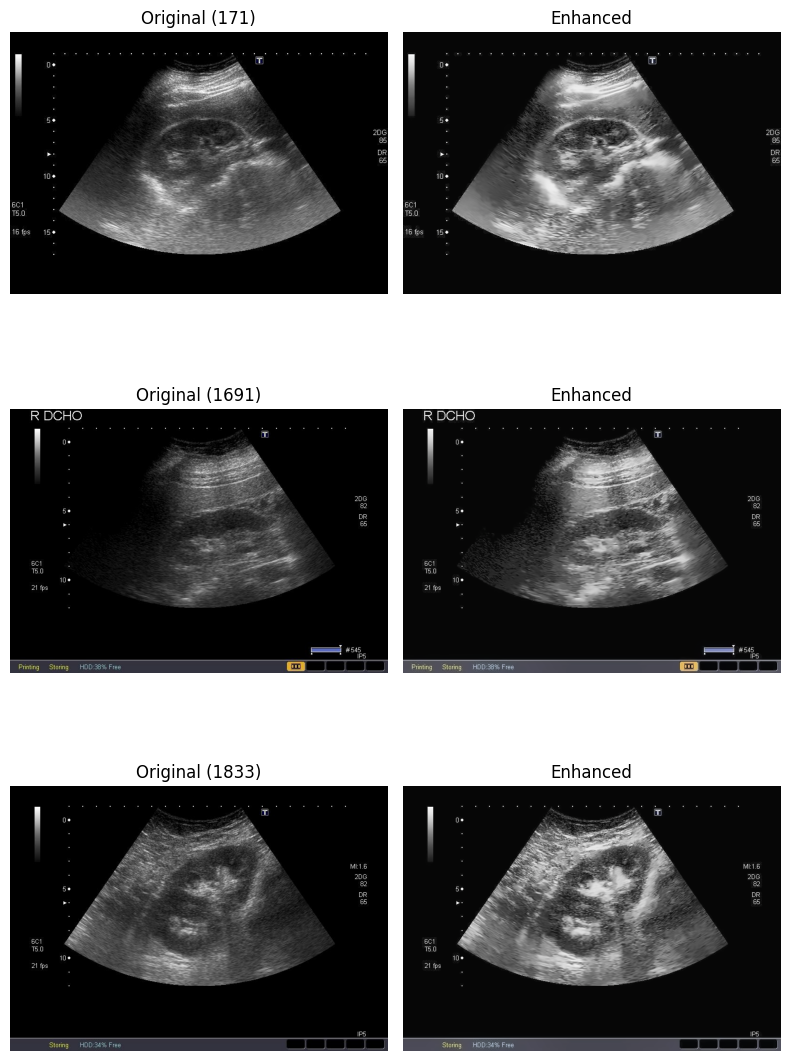

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

sample_rows = manifest.sample(3, random_state=1)

fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for i, (_, row) in enumerate(sample_rows.iterrows()):
    original = np.array(Image.open(row['image_path']).convert('RGB'))
    enhanced = enhance_ultrasound(original)

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f'Original ({row["case_id"]})')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(enhanced)
    axes[i, 1].set_title('Enhanced')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

## STOP AND CHECK

Look at the plotted images above. If enhanced versions look reasonable, continue. If something looks badly wrong, tell me and we'll adjust `ENHANCEMENT_PARAMS` before training on it.

## Dataset class (same as Phase 2, with enhancement inserted before normalization)

In [9]:
from torch.utils.data import Dataset, DataLoader
import scipy.io

IMG_SIZE = (512, 512)


def load_kidney_mask(mat_path):
    data = scipy.io.loadmat(mat_path)
    mask = data['mask']
    return np.asarray(mask).astype(np.uint8)


class URICADSDatasetEnhanced(Dataset):
    def __init__(self, manifest_df, img_size=IMG_SIZE, apply_enhancement=True):
        self.manifest = manifest_df.reset_index(drop=True)
        self.img_size = img_size
        self.apply_enhancement = apply_enhancement

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        target_h, target_w = self.img_size

        image = Image.open(row['image_path']).convert('RGB')
        image = image.resize((target_w, target_h), Image.BILINEAR)
        image = np.array(image).astype(np.uint8)

        if self.apply_enhancement:
            image = enhance_ultrasound(image)

        image = image.astype(np.float32) / 255.0
        image = (image - 0.5) / 0.5

        kidney_mask = load_kidney_mask(row['mask_path'])
        kidney_mask = np.array(Image.fromarray(kidney_mask).resize((target_w, target_h), Image.NEAREST))

        global_diagnosis = int(row['global_diagnosis'])
        global_pathologies = torch.tensor(row['global_pathologies'], dtype=torch.float32)

        image_tensor = torch.from_numpy(image).permute(2, 0, 1).float()
        kidney_mask_tensor = torch.from_numpy(kidney_mask).float()

        return {
            'image': image_tensor,
            'kidney_mask': kidney_mask_tensor,
            'global_diagnosis': torch.tensor(global_diagnosis, dtype=torch.float32),
            'global_pathologies': global_pathologies,
            'case_id': row['case_id'],
        }


train_ds = URICADSDatasetEnhanced(manifest[manifest['split'] == 'train'])
val_ds = URICADSDatasetEnhanced(manifest[manifest['split'] == 'val'])
test_ds = URICADSDatasetEnhanced(manifest[manifest['split'] == 'test'])

print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')
sample = train_ds[0]
print({k: (v.shape if hasattr(v, 'shape') else v) for k, v in sample.items()})

Train: 1389 | Val: 298 | Test: 298
{'image': torch.Size([3, 512, 512]), 'kidney_mask': torch.Size([512, 512]), 'global_diagnosis': torch.Size([]), 'global_pathologies': torch.Size([2]), 'case_id': '10'}


## Model (identical architecture to Phase 2 -- only the input preprocessing differs)

In [10]:
import torch.nn as nn
import torchvision

NUM_GLOBAL_PATHOLOGIES = len(manifest.iloc[0]['global_pathologies'])


class MultiTaskNet(nn.Module):
    def __init__(self, num_global_pathologies=2, pretrained=True):
        super().__init__()
        backbone = torchvision.models.resnet34(weights='IMAGENET1K_V1' if pretrained else None)
        self.encoder = nn.Sequential(*list(backbone.children())[:-2])
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.diagnosis_head = nn.Linear(512, 1)
        self.global_pathology_head = nn.Linear(512, num_global_pathologies)

        def up_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            )

        self.seg_decoder = nn.Sequential(
            up_block(512, 256), up_block(256, 128), up_block(128, 64),
            up_block(64, 32), up_block(32, 16),
            nn.Conv2d(16, 1, kernel_size=1),
        )

    def forward(self, x):
        feat = self.encoder(x)
        pooled = self.global_pool(feat).flatten(1)
        diagnosis_logits = self.diagnosis_head(pooled).squeeze(1)
        global_pathology_logits = self.global_pathology_head(pooled)
        seg_logits = self.seg_decoder(feat).squeeze(1)
        return diagnosis_logits, global_pathology_logits, seg_logits


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MultiTaskNet(num_global_pathologies=NUM_GLOBAL_PATHOLOGIES).to(device)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 172MB/s]


## Loss (identical to Phase 2 -- fixed equal weights, isolating enhancement as the only variable)

In [11]:
def dice_loss(pred_logits, target, eps=1e-6):
    pred = torch.sigmoid(pred_logits)
    pred_flat = pred.flatten(1)
    target_flat = target.flatten(1)
    intersection = (pred_flat * target_flat).sum(dim=1)
    union = pred_flat.sum(dim=1) + target_flat.sum(dim=1)
    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice.mean()


bce_logits = nn.BCEWithLogitsLoss()


def compute_loss(diagnosis_logits, global_pathology_logits, seg_logits, batch):
    diagnosis_target = batch['global_diagnosis'].to(device)
    global_pathology_target = batch['global_pathologies'].to(device)
    seg_target = batch['kidney_mask'].to(device)

    loss_diagnosis = bce_logits(diagnosis_logits, diagnosis_target)
    loss_global = bce_logits(global_pathology_logits, global_pathology_target)
    loss_seg = dice_loss(seg_logits, seg_target)

    total_loss = loss_diagnosis + loss_global + loss_seg
    return total_loss, {
        'diagnosis': loss_diagnosis.item(),
        'global_pathology': loss_global.item(),
        'seg': loss_seg.item(),
    }

## Training setup -- run this cell, then the definitions cell, then the tiny test, THEN the full loop

In [12]:
BATCH_SIZE = 4
NUM_EPOCHS = 10
LEARNING_RATE = 1e-4

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [13]:
from tqdm.auto import tqdm


def dice_score(pred_logits, target, eps=1e-6):
    pred = (torch.sigmoid(pred_logits) > 0.5).float()
    pred_flat = pred.flatten(1)
    target_flat = target.flatten(1)
    intersection = (pred_flat * target_flat).sum(dim=1)
    union = pred_flat.sum(dim=1) + target_flat.sum(dim=1)
    return ((2 * intersection + eps) / (union + eps)).mean().item()


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss = 0.0
    total_dice = 0.0
    n_batches = 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for batch in tqdm(loader, desc='train' if train else 'val'):
            images = batch['image'].to(device)
            diagnosis_logits, global_pathology_logits, seg_logits = model(images)
            loss, _ = compute_loss(diagnosis_logits, global_pathology_logits, seg_logits, batch)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            total_dice += dice_score(seg_logits, batch['kidney_mask'].to(device))
            n_batches += 1
    return total_loss / n_batches, total_dice / n_batches

## Tiny sanity test -- run this BEFORE the full loop

In [14]:
tiny_train = torch.utils.data.Subset(train_ds, range(20))
tiny_loader = DataLoader(tiny_train, batch_size=4, num_workers=0)
t0 = time.time()
run_epoch(tiny_loader, train=True)
print(f'20 samples took {time.time()-t0:.1f}s')
print('If this took more than ~10-15s, flag it before running the full loop -- CLAHE/denoising add CPU overhead per image.')

train:   0%|          | 0/5 [00:00<?, ?it/s]

20 samples took 18.3s
If this took more than ~10-15s, flag it before running the full loop -- CLAHE/denoising add CPU overhead per image.


## Full training loop (only run after the tiny test looks reasonable)

In [15]:
best_val_dice = 0.0
for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_dice = run_epoch(train_loader, train=True)
    val_loss, val_dice = run_epoch(val_loader, train=False)
    elapsed = time.time() - t0

    print(f'Epoch {epoch:2d}/{NUM_EPOCHS} | '
          f'train_loss={train_loss:.4f} train_dice={train_dice:.4f} | '
          f'val_loss={val_loss:.4f} val_dice={val_dice:.4f} | {elapsed:.1f}s')

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        checkpoint_path = os.path.join(DRIVE_CHECKPOINTS_PATH, 'phase3_enhanced_best.pt')
        torch.save(model.state_dict(), checkpoint_path)
        print(f'  -> new best val_dice={val_dice:.4f}, checkpoint saved to Drive')

train:   0%|          | 0/348 [00:00<?, ?it/s]

val:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch  1/10 | train_loss=1.8158 train_dice=0.6620 | val_loss=1.6984 val_dice=0.6889 | 1430.6s
  -> new best val_dice=0.6889, checkpoint saved to Drive


train:   0%|          | 0/348 [00:00<?, ?it/s]

val:   0%|          | 0/75 [00:00<?, ?it/s]

...

val:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch  9/10 | train_loss=0.5338 train_dice=0.8743 | val_loss=1.2251 val_dice=0.8739 | 1423.9s
  -> new best val_dice=0.8739, checkpoint saved to Drive


train:   0%|          | 0/348 [00:00<?, ?it/s]

val:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch 10/10 | train_loss=0.3789 train_dice=0.8919 | val_loss=1.1943 val_dice=0.8780 | 1414.1s
  -> new best val_dice=0.8780, checkpoint saved to Drive


## Test-set evaluation -- compare directly against Phase 2's numbers

In [16]:
from sklearn.metrics import roc_auc_score

test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model.load_state_dict(torch.load(os.path.join(DRIVE_CHECKPOINTS_PATH, 'phase3_enhanced_best.pt')))
model.eval()

all_diag_probs, all_diag_targets = [], []
all_dice_scores = []

with torch.no_grad():
    for batch in test_loader:
        images = batch['image'].to(device)
        diagnosis_logits, global_pathology_logits, seg_logits = model(images)
        all_diag_probs.extend(torch.sigmoid(diagnosis_logits).cpu().numpy())
        all_diag_targets.extend(batch['global_diagnosis'].numpy())
        all_dice_scores.append(dice_score(seg_logits, batch['kidney_mask'].to(device)))

test_auc = roc_auc_score(all_diag_targets, all_diag_probs)
test_dice = sum(all_dice_scores) / len(all_dice_scores)

print('PHASE 3 RESULTS (fixed-parameter enhancement + fixed equal loss weights):')
print(f'  Healthy/Pathological AUC : {test_auc:.4f}   (Phase 2 baseline: 0.9003)')
print(f'  Kidney Segmentation Dice : {test_dice:.4f}   (Phase 2 baseline: 0.8735)')
print()
print('If these numbers are close to or worse than Phase 2, that is a real, useful finding --')
print('it means fixed-parameter enhancement alone does not help, which is exactly the motivation')
print('for optimizing the enhancement parameters in Phase 6 instead of hand-picking them.')

PHASE 3 RESULTS (fixed-parameter enhancement + fixed equal loss weights):
  Healthy/Pathological AUC : 0.8712   (Phase 2 baseline: 0.9003)
  Kidney Segmentation Dice : 0.8891   (Phase 2 baseline: 0.8735)

If these numbers are close to or worse than Phase 2, that is a real, useful finding --
it means fixed-parameter enhancement alone does not help, which is exactly the motivation
for optimizing the enhancement parameters in Phase 6 instead of hand-picking them.
